# Digital Image Processing – Lab Task #04
## Geometric Transformations with Custom Inputs

**University:** The University of Azad Jammu and Kashmir  
**Department:** Software Engineering  
**Student Name:** Zoya Mazhar
**Roll Number:** 2024-SE-26 
**Semester:** Fifth  
**Lab Instructor:** Engr. Fahad Nisar  

**Input image:** `image.jpg`

### Objective
Create one reusable function named `transform` that performs geometric transformations using custom parameters and validates the inputs.

## 1. Import required libraries

We use:
- **OpenCV (`cv2`)** for image transformations.
- **NumPy** for image arrays and numeric checks.
- **Matplotlib** to display images.
- **os** to check files and save results.
- **math** to check finite numbers.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import math

## 2. Load and validate the image

The image file must exist, must be readable, and must have a width and height greater than zero. OpenCV loads images in BGR colour order, so we convert the image to RGB for correct display in Matplotlib.

The original image is kept unchanged. All transformations use a copy or create a new image.

In [2]:
image_path = "image.jpg"

if not os.path.exists(image_path):
    raise FileNotFoundError("The file 'image.jpg' was not found. Keep it in the same folder as this notebook.")

image = cv2.imread(image_path)

if image is None:
    raise ValueError("The image file exists, but OpenCV could not read it.")

height, width = image.shape[:2]

if height == 0 or width == 0:
    raise ValueError("The image has an empty width or height.")

original_image = image.copy()

print("Image loaded successfully.")
print("Width:", width, "pixels")
print("Height:", height, "pixels")
print("Array shape:", image.shape)
print("Colour channels: 3 (BGR)")

Image loaded successfully.
Width: 559 pixels
Height: 548 pixels
Array shape: (548, 559, 3)
Colour channels: 3 (BGR)


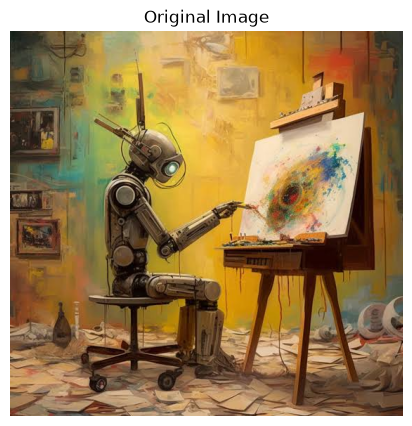

In [3]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(7, 5))
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

## 3. Reusable transformation function

This is the main function of the lab. It accepts:
- an image,
- an operation name,
- custom parameters for that operation.

It returns a new transformed image. It does not change the original image.

**Maximum output size:** 20 million pixels. This limit helps prevent creating an extremely large image by mistake.

In [4]:
MAX_OUTPUT_PIXELS = 20_000_000

def check_finite_number(value, parameter_name):
    try:
        number = float(value)
    except (TypeError, ValueError):
        raise ValueError(parameter_name + " must be a number.")

    if not math.isfinite(number):
        raise ValueError(parameter_name + " must be finite (not NaN or infinity).")

    return number


def transform(input_image, operation, **params):
    if input_image is None or not isinstance(input_image, np.ndarray):
        raise ValueError("Please provide a valid image.")

    if input_image.size == 0:
        raise ValueError("The input image is empty.")

    height, width = input_image.shape[:2]
    if height < 1 or width < 1:
        raise ValueError("The input image must have nonzero dimensions.")

    result = None

    if operation == "scale":
        if "scale_x" not in params or "scale_y" not in params or "interpolation" not in params:
            raise ValueError("Scaling needs scale_x, scale_y, and interpolation.")

        scale_x = check_finite_number(params["scale_x"], "Horizontal scale factor")
        scale_y = check_finite_number(params["scale_y"], "Vertical scale factor")

        if scale_x <= 0 or scale_y <= 0:
            raise ValueError("Scale factors must be greater than zero.")

        interpolation_choices = {
            "nearest": cv2.INTER_NEAREST,
            "bilinear": cv2.INTER_LINEAR,
            "bicubic": cv2.INTER_CUBIC,
            "lanczos": cv2.INTER_LANCZOS4
        }

        interpolation_name = str(params["interpolation"]).lower()
        if interpolation_name not in interpolation_choices:
            raise ValueError("Interpolation must be nearest, bilinear, bicubic, or lanczos.")

        new_width = int(round(width * scale_x))
        new_height = int(round(height * scale_y))

        if new_width < 1 or new_height < 1:
            raise ValueError("The new image dimensions must be at least one pixel.")

        if new_width * new_height > MAX_OUTPUT_PIXELS:
            raise ValueError("The output image is too large. Reduce the scale factors.")

        result = cv2.resize(
            input_image,
            (new_width, new_height),
            interpolation=interpolation_choices[interpolation_name]
        )

    elif operation == "crop":
        required = ["left", "top", "right", "bottom"]
        for name in required:
            if name not in params:
                raise ValueError("Cropping needs left, top, right, and bottom.")

            value = params[name]
            if isinstance(value, bool) or not isinstance(value, (int, np.integer)):
                raise ValueError(name + " must be an integer.")

        left = params["left"]
        top = params["top"]
        right = params["right"]
        bottom = params["bottom"]

        if not (0 <= left < right <= width):
            raise ValueError("Crop coordinates must satisfy 0 <= left < right <= image width.")
        if not (0 <= top < bottom <= height):
            raise ValueError("Crop coordinates must satisfy 0 <= top < bottom <= image height.")

        result = input_image[top:bottom, left:right].copy()

        if result.size == 0:
            raise ValueError("The crop would create an empty image.")

    elif operation == "flip":
        if "direction" not in params:
            raise ValueError("Flipping needs a direction: horizontal, vertical, or both.")

        direction = str(params["direction"]).lower()
        flip_values = {"horizontal": 1, "vertical": 0, "both": -1}

        if direction not in flip_values:
            raise ValueError("Direction must be horizontal, vertical, or both.")

        result = cv2.flip(input_image, flip_values[direction])

    elif operation == "translate":
        if "tx" not in params or "ty" not in params:
            raise ValueError("Translation needs tx and ty.")

        tx = check_finite_number(params["tx"], "Horizontal offset tx")
        ty = check_finite_number(params["ty"], "Vertical offset ty")

        matrix = np.float32([[1, 0, tx], [0, 1, ty]])
        result = cv2.warpAffine(
            input_image, matrix, (width, height),
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=(0, 0, 0)
        )

    elif operation == "rotate":
        if "angle" not in params or "expand" not in params:
            raise ValueError("Rotation needs angle and expand.")

        angle = check_finite_number(params["angle"], "Rotation angle")
        expand = params["expand"]

        if not isinstance(expand, (bool, np.bool_)):
            raise ValueError("expand must be True or False.")

        centre = (width / 2, height / 2)
        matrix = cv2.getRotationMatrix2D(centre, angle, 1.0)

        if expand:
            cosine = abs(matrix[0, 0])
            sine = abs(matrix[0, 1])
            new_width = int(round((height * sine) + (width * cosine)))
            new_height = int(round((height * cosine) + (width * sine)))

            if new_width < 1 or new_height < 1:
                raise ValueError("Rotation would create an empty image.")
            if new_width * new_height > MAX_OUTPUT_PIXELS:
                raise ValueError("The rotated image is too large.")

            matrix[0, 2] += (new_width / 2) - centre[0]
            matrix[1, 2] += (new_height / 2) - centre[1]
            output_size = (new_width, new_height)
        else:
            output_size = (width, height)

        result = cv2.warpAffine(
            input_image, matrix, output_size,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=(0, 0, 0)
        )

    else:
        raise ValueError("Unknown operation. Use scale, crop, flip, translate, or rotate.")

    if result is None or result.size == 0:
        raise ValueError("The operation did not produce a valid image.")

    return result

## 4. Helper function to display and save results

The following helper displays the original image beside the result. It also shows the operation name, parameters, and output dimensions, and saves the transformed image in the `transformed_images` folder.

In [5]:
output_folder = "transformed_images"
os.makedirs(output_folder, exist_ok=True)

def show_and_save(result, title, file_name):
    result_rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)
    result_height, result_width = result.shape[:2]

    print(title)
    print("Output width:", result_width, "pixels")
    print("Output height:", result_height, "pixels")
    print("Output shape:", result.shape)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB))
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(result_rgb)
    plt.title(title)
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    save_path = os.path.join(output_folder, file_name)
    cv2.imwrite(save_path, result)
    print("Saved:", save_path)
    print("-" * 55)

## 5. Scaling / resizing

Scaling changes image width and height. A factor greater than 1 enlarges the image. A factor between 0 and 1 reduces it.

- Proportional scaling uses the same horizontal and vertical factor.
- Non-proportional scaling uses different factors and can change the image's aspect ratio.

Scaling: proportional enlargement (1.5, 1.5)
Output width: 838 pixels
Output height: 822 pixels
Output shape: (822, 838, 3)


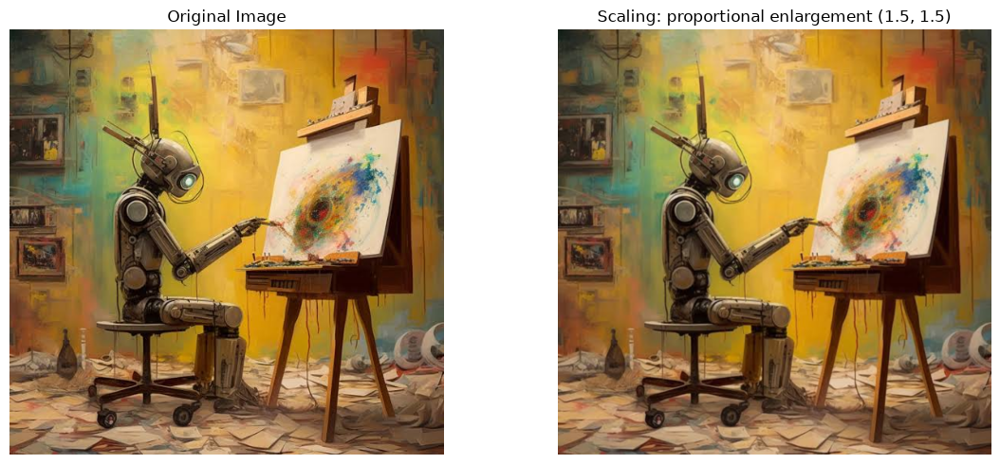

Saved: transformed_images\01_scale_enlarge.jpg
-------------------------------------------------------
Scaling: proportional reduction (0.6, 0.6)
Output width: 335 pixels
Output height: 329 pixels
Output shape: (329, 335, 3)


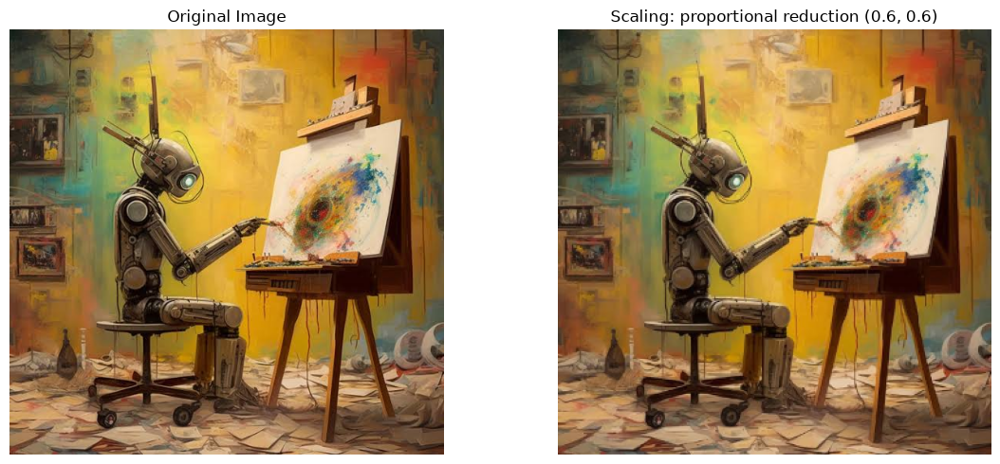

Saved: transformed_images\02_scale_reduce.jpg
-------------------------------------------------------
Scaling: non-proportional (1.3, 0.8)
Output width: 727 pixels
Output height: 438 pixels
Output shape: (438, 727, 3)


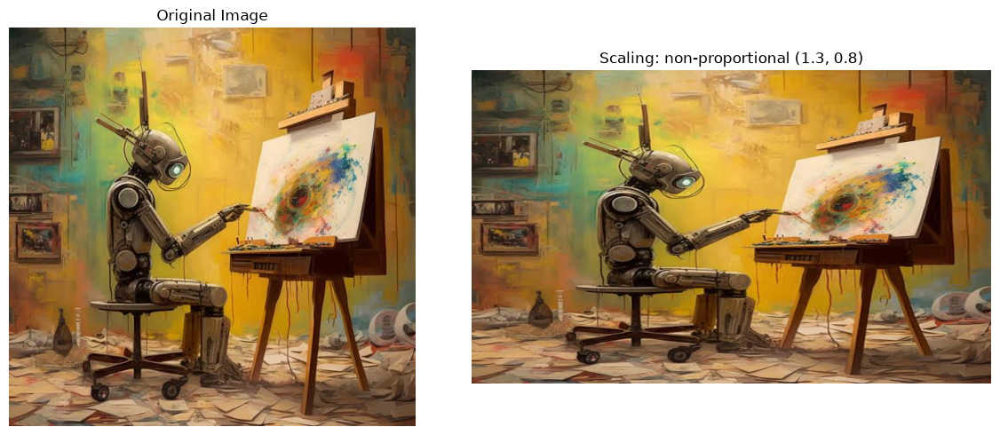

Saved: transformed_images\03_scale_nonproportional.jpg
-------------------------------------------------------


In [6]:
# Proportional enlargement
scaled_large = transform(image, "scale", scale_x=1.5, scale_y=1.5, interpolation="bilinear")
show_and_save(scaled_large, "Scaling: proportional enlargement (1.5, 1.5)", "01_scale_enlarge.jpg")

# Proportional reduction
scaled_small = transform(image, "scale", scale_x=0.6, scale_y=0.6, interpolation="bilinear")
show_and_save(scaled_small, "Scaling: proportional reduction (0.6, 0.6)", "02_scale_reduce.jpg")

# Non-proportional scaling
scaled_nonproportional = transform(image, "scale", scale_x=1.3, scale_y=0.8, interpolation="bicubic")
show_and_save(scaled_nonproportional, "Scaling: non-proportional (1.3, 0.8)", "03_scale_nonproportional.jpg")

## 6. Cropping

Cropping selects a rectangular part of the image. The right and bottom coordinates are exclusive, which means the pixel at those positions is not included.

The values below are calculated from the image dimensions so the crop stays inside the image.

Cropping: left=83, top=82, right=447, bottom=438
Output width: 364 pixels
Output height: 356 pixels
Output shape: (356, 364, 3)


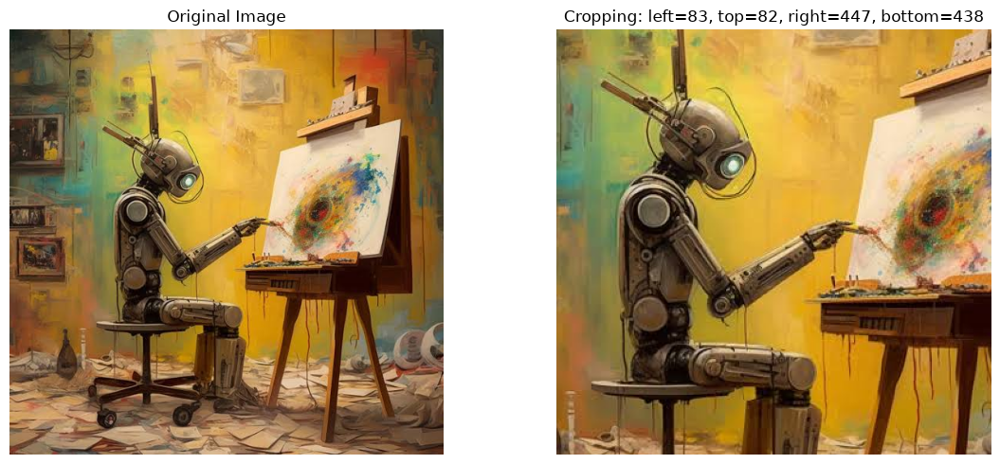

Saved: transformed_images\04_crop.jpg
-------------------------------------------------------


In [7]:
left = int(width * 0.15)
top = int(height * 0.15)
right = int(width * 0.80)
bottom = int(height * 0.80)

cropped_image = transform(
    image, "crop",
    left=left, top=top, right=right, bottom=bottom
)
show_and_save(
    cropped_image,
    "Cropping: left={}, top={}, right={}, bottom={}".format(left, top, right, bottom),
    "04_crop.jpg"
)

## 7. Flipping

Flipping creates a mirror-like result.

- **Horizontal:** flips left to right.
- **Vertical:** flips top to bottom.
- **Both:** flips in both directions.

All three required results are shown below.

Flipping: horizontal
Output width: 559 pixels
Output height: 548 pixels
Output shape: (548, 559, 3)


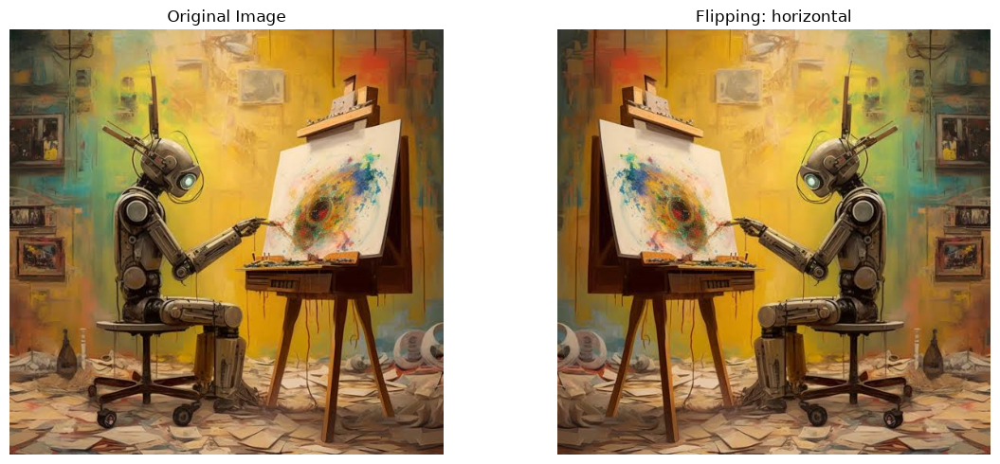

Saved: transformed_images\05_flip_horizontal.jpg
-------------------------------------------------------
Flipping: vertical
Output width: 559 pixels
Output height: 548 pixels
Output shape: (548, 559, 3)


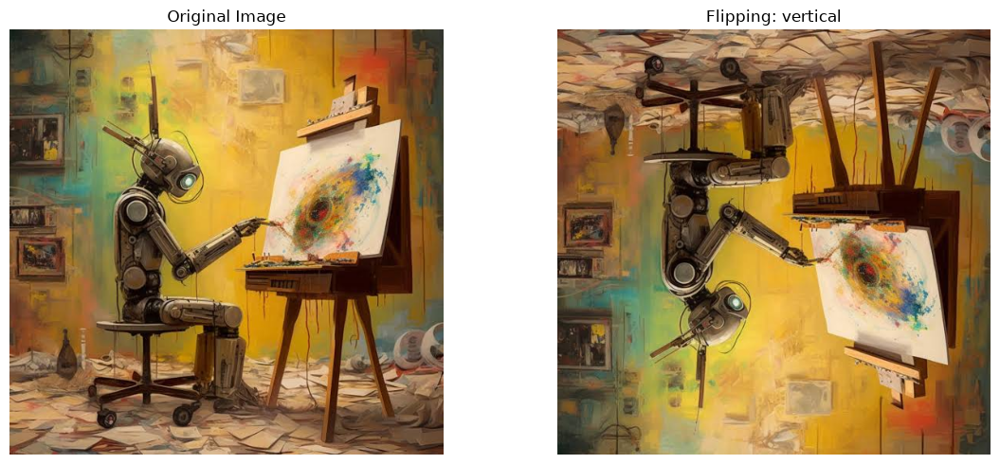

Saved: transformed_images\06_flip_vertical.jpg
-------------------------------------------------------
Flipping: both directions
Output width: 559 pixels
Output height: 548 pixels
Output shape: (548, 559, 3)


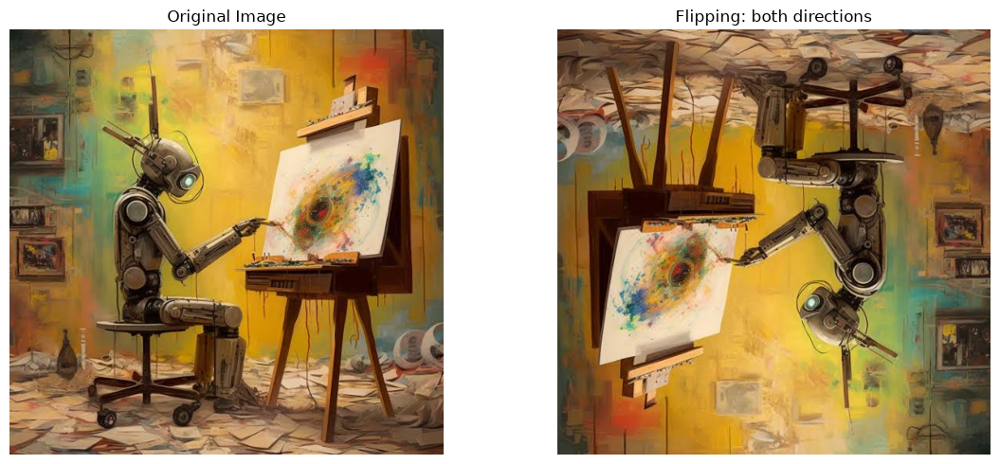

Saved: transformed_images\07_flip_both.jpg
-------------------------------------------------------


In [8]:
flip_horizontal = transform(image, "flip", direction="horizontal")
show_and_save(flip_horizontal, "Flipping: horizontal", "05_flip_horizontal.jpg")

flip_vertical = transform(image, "flip", direction="vertical")
show_and_save(flip_vertical, "Flipping: vertical", "06_flip_vertical.jpg")

flip_both = transform(image, "flip", direction="both")
show_and_save(flip_both, "Flipping: both directions", "07_flip_both.jpg")

## 8. Translation

Translation moves the image horizontally and/or vertically while keeping the original canvas size.

- Positive `tx` moves the image right; negative `tx` moves it left.
- Positive `ty` moves the image down; negative `ty` moves it up.

Parts that move outside the fixed canvas are clipped. Newly exposed areas are filled with black pixels.

Translation: tx=60, ty=35 (right and down)
Output width: 559 pixels
Output height: 548 pixels
Output shape: (548, 559, 3)


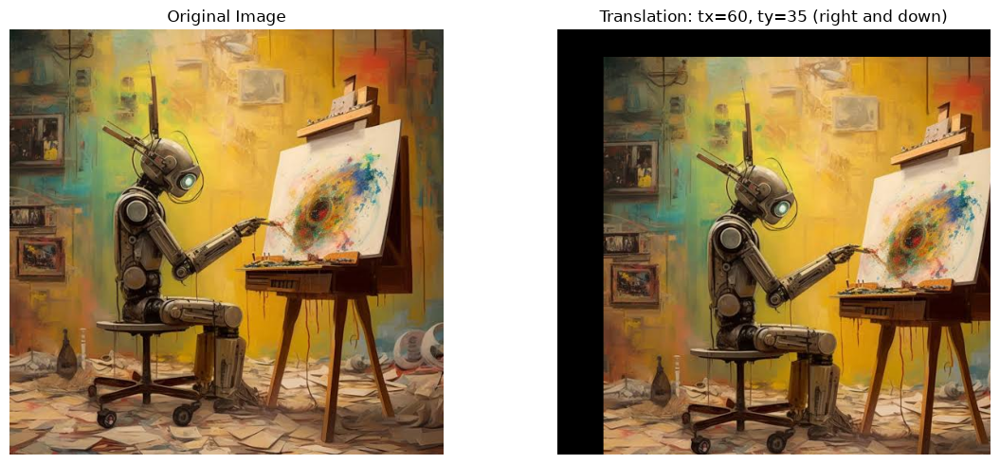

Saved: transformed_images\08_translate_right_down.jpg
-------------------------------------------------------
Translation: tx=-60, ty=-35 (left and up)
Output width: 559 pixels
Output height: 548 pixels
Output shape: (548, 559, 3)


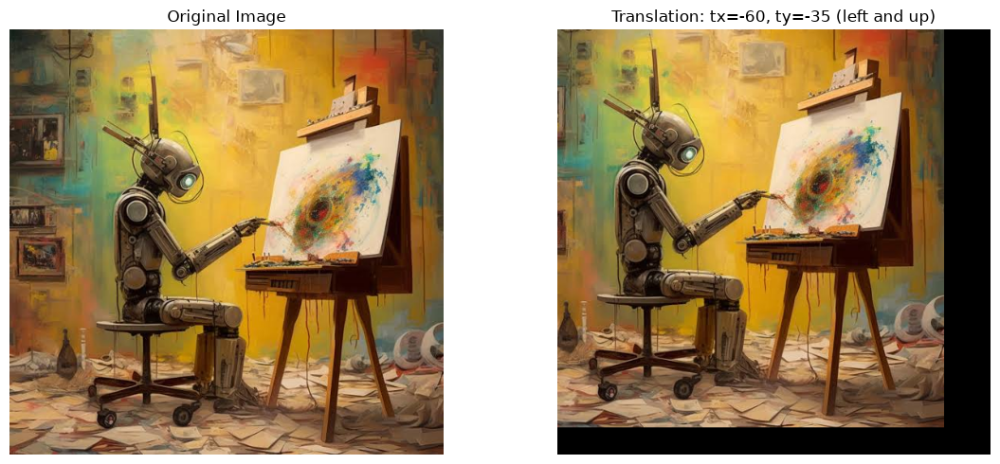

Saved: transformed_images\09_translate_left_up.jpg
-------------------------------------------------------


In [9]:
translated_right_down = transform(image, "translate", tx=60, ty=35)
show_and_save(translated_right_down, "Translation: tx=60, ty=35 (right and down)", "08_translate_right_down.jpg")

translated_left_up = transform(image, "translate", tx=-60, ty=-35)
show_and_save(translated_left_up, "Translation: tx=-60, ty=-35 (left and up)", "09_translate_left_up.jpg")

# Identity case: no movement
translated_zero = transform(image, "translate", tx=0, ty=0)

## 9. Rotation

Rotation turns the image around its centre.

OpenCV uses positive angles for counter-clockwise rotation and negative angles for clockwise rotation. If `expand=True`, the output canvas becomes large enough to contain the rotated image. If `expand=False`, the original canvas size is kept, so some corners may be clipped.

Rotation: +30 degrees, canvas expanded
Output width: 758 pixels
Output height: 754 pixels
Output shape: (754, 758, 3)


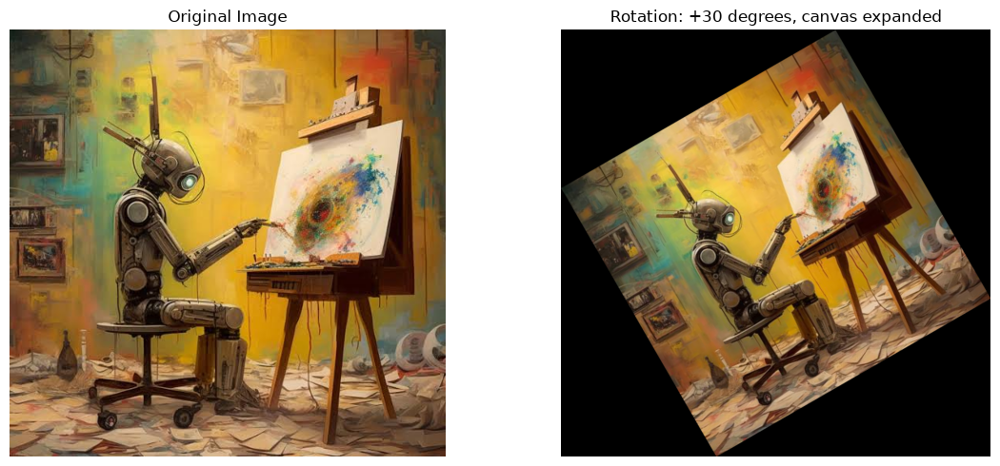

Saved: transformed_images\10_rotate_positive.jpg
-------------------------------------------------------
Rotation: -30 degrees, canvas expanded
Output width: 758 pixels
Output height: 754 pixels
Output shape: (754, 758, 3)


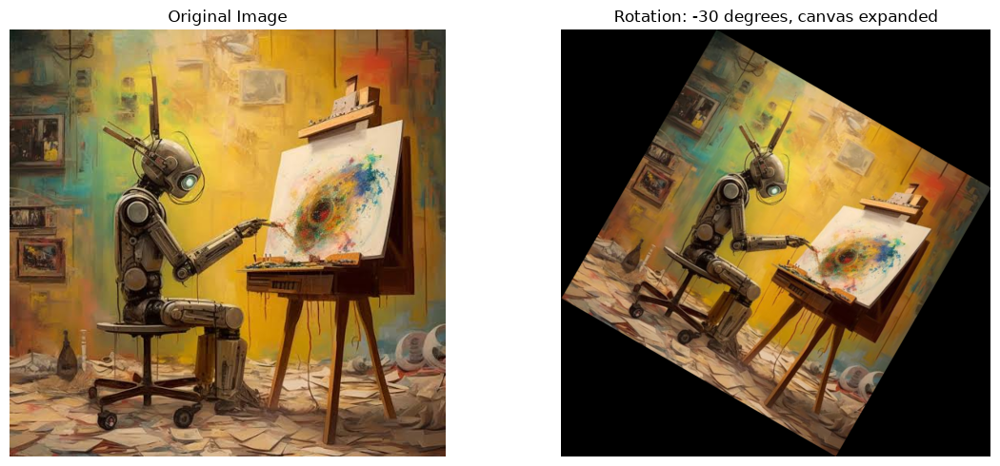

Saved: transformed_images\11_rotate_negative.jpg
-------------------------------------------------------
Rotation: +30 degrees, original canvas
Output width: 559 pixels
Output height: 548 pixels
Output shape: (548, 559, 3)


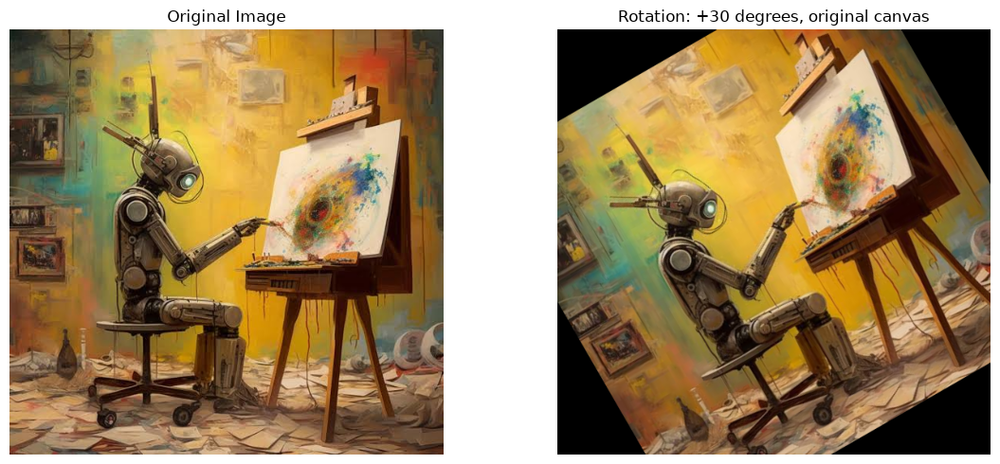

Saved: transformed_images\12_rotate_fixed_canvas.jpg
-------------------------------------------------------


In [10]:
rotated_positive = transform(image, "rotate", angle=30, expand=True)
show_and_save(rotated_positive, "Rotation: +30 degrees, canvas expanded", "10_rotate_positive.jpg")

rotated_negative = transform(image, "rotate", angle=-30, expand=True)
show_and_save(rotated_negative, "Rotation: -30 degrees, canvas expanded", "11_rotate_negative.jpg")

rotated_fixed_canvas = transform(image, "rotate", angle=30, expand=False)
show_and_save(rotated_fixed_canvas, "Rotation: +30 degrees, original canvas", "12_rotate_fixed_canvas.jpg")

# Identity case: zero degree rotation
rotated_zero = transform(image, "rotate", angle=0, expand=False)

## 10. Affine transformation matrices

Translation and rotation are examples of **affine transformations**. An affine transformation uses a 2 × 3 matrix to change image coordinates. This extra demonstration prints the matrices used for translation and rotation. The transformed images are already displayed and saved in the previous sections.

In [11]:
# Affine matrix for translation
translation_matrix = np.float32([
    [1, 0, 60],
    [0, 1, 35]
])

# Affine matrix for rotation around the image centre
rotation_matrix = cv2.getRotationMatrix2D(
    (width / 2, height / 2),
    30,
    1.0
)

print("Translation affine matrix:")
print(translation_matrix)

print("\\nRotation affine matrix (+30 degrees):")
print(rotation_matrix)

# Apply the translation matrix while keeping the original canvas size
affine_translation_result = cv2.warpAffine(
    image, translation_matrix, (width, height)
)

print("\\nAffine translation output shape:", affine_translation_result.shape)
print("This is the same type of affine operation demonstrated in the translation section.")

Translation affine matrix:
[[ 1.  0. 60.]
 [ 0.  1. 35.]]
\nRotation affine matrix (+30 degrees):
[[  0.8660254    0.5        -99.55410036]
 [ -0.5          0.8660254  176.45903936]]
\nAffine translation output shape: (548, 559, 3)
This is the same type of affine operation demonstrated in the translation section.


## 11. Interpolation comparison

Interpolation decides how new pixel values are calculated when an image is enlarged. We use the same enlarged image patch for all four methods.

- **Nearest-neighbour:** uses the nearest existing pixel. It can look blocky.
- **Bilinear:** uses nearby pixels and usually looks smoother.
- **Bicubic:** uses a larger neighbourhood and can preserve smoother detail.
- **Lanczos:** uses a wider sampling area and often gives sharp results.

The exact visible result depends on the image and enlargement amount.

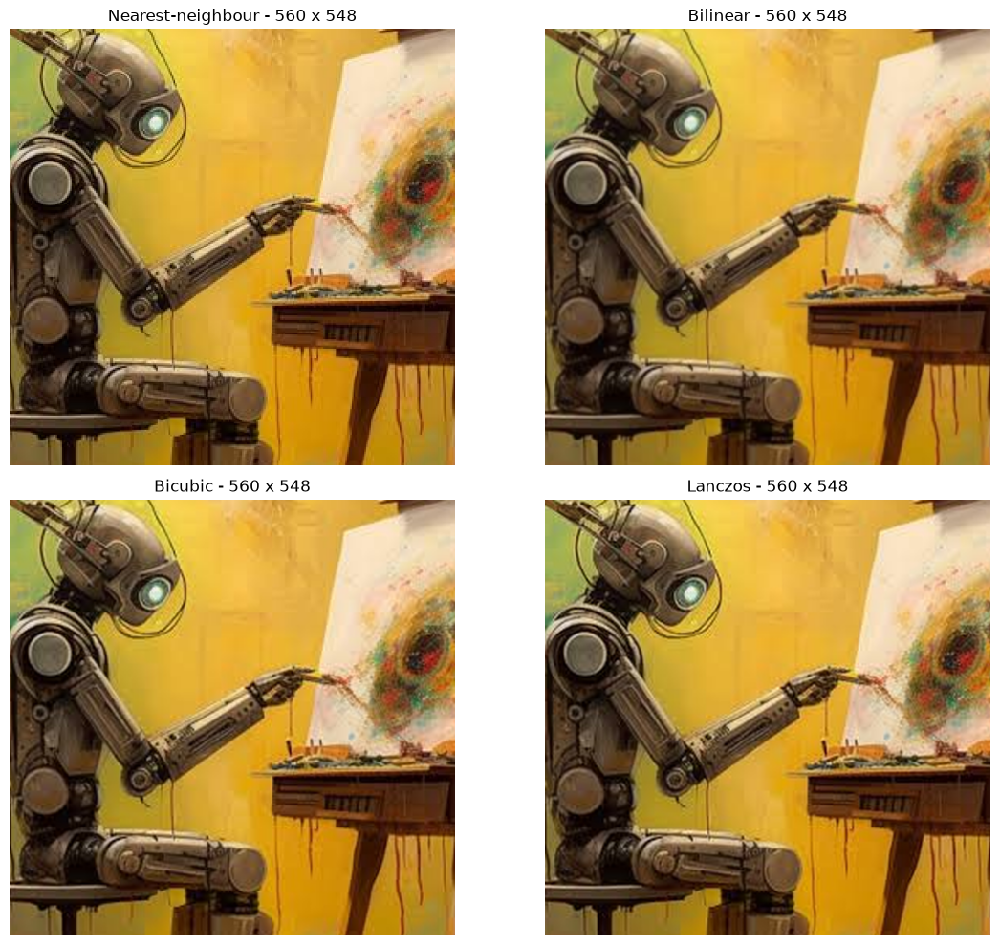

All four methods used the same patch and output dimensions: 560 x 548 pixels.


In [12]:
# Select the same central patch for every interpolation method
patch_left = int(width * 0.25)
patch_top = int(height * 0.25)
patch_right = int(width * 0.75)
patch_bottom = int(height * 0.75)

image_patch = image[patch_top:patch_bottom, patch_left:patch_right].copy()

if image_patch.size == 0:
    raise ValueError("The selected image patch is empty.")

patch_height, patch_width = image_patch.shape[:2]
large_size = (patch_width * 2, patch_height * 2)

interpolation_methods = [
    ("Nearest-neighbour", cv2.INTER_NEAREST),
    ("Bilinear", cv2.INTER_LINEAR),
    ("Bicubic", cv2.INTER_CUBIC),
    ("Lanczos", cv2.INTER_LANCZOS4)
]

plt.figure(figsize=(12, 10))
for index, (method_name, method_value) in enumerate(interpolation_methods, start=1):
    enlarged_patch = cv2.resize(image_patch, large_size, interpolation=method_value)
    plt.subplot(2, 2, index)
    plt.imshow(cv2.cvtColor(enlarged_patch, cv2.COLOR_BGR2RGB))
    plt.title(method_name + " - " + str(enlarged_patch.shape[1]) + " x " + str(enlarged_patch.shape[0]))
    plt.axis("off")

    cv2.imwrite(
        os.path.join(output_folder, "interpolation_" + method_name.lower().replace("-", "_") + ".jpg"),
        enlarged_patch
    )

plt.tight_layout()
plt.show()
print("All four methods used the same patch and output dimensions:", large_size[0], "x", large_size[1], "pixels.")

## 12. Input validation demonstrations

Each test below intentionally provides an invalid value. The function should reject it with a clear error message instead of stopping the whole notebook.

In [13]:
def show_rejected_input(test_name, operation, **params):
    try:
        transform(image, operation, **params)
        print(test_name + ": FAIL - invalid input was accepted.")
    except (ValueError, TypeError) as error:
        print(test_name + ": PASS - rejected correctly.")
        print("Message:", error)
    print("-" * 50)


# Scaling: zero scale factor is not allowed
show_rejected_input(
    "Invalid scaling",
    "scale", scale_x=0, scale_y=1, interpolation="bilinear"
)

# Cropping: right coordinate is not greater than left
show_rejected_input(
    "Invalid cropping",
    "crop", left=100, top=20, right=50, bottom=100
)

# Flipping: unsupported direction
show_rejected_input(
    "Invalid flipping",
    "flip", direction="diagonal"
)

# Translation: infinity is not allowed
show_rejected_input(
    "Invalid translation",
    "translate", tx=float("inf"), ty=10
)

# Rotation: nonnumeric angle is not allowed
show_rejected_input(
    "Invalid rotation",
    "rotate", angle="not-a-number", expand=True
)

# Scaling: unsupported interpolation choice is not allowed
show_rejected_input(
    "Unsupported interpolation",
    "scale", scale_x=1.2, scale_y=1.2, interpolation="unknown"
)


Invalid scaling: PASS - rejected correctly.
Message: Scale factors must be greater than zero.
--------------------------------------------------
Invalid cropping: PASS - rejected correctly.
Message: Crop coordinates must satisfy 0 <= left < right <= image width.
--------------------------------------------------
Invalid flipping: PASS - rejected correctly.
Message: Direction must be horizontal, vertical, or both.
--------------------------------------------------
Invalid translation: PASS - rejected correctly.
Message: Horizontal offset tx must be finite (not NaN or infinity).
--------------------------------------------------
Invalid rotation: PASS - rejected correctly.
Message: Rotation angle must be a number.
--------------------------------------------------
Unsupported interpolation: PASS - rejected correctly.
Message: Interpolation must be nearest, bilinear, bicubic, or lanczos.
--------------------------------------------------


## 13. Identity checks

An identity transformation should leave the image unchanged:
- Scaling by 1 horizontally and vertically.
- Translation by 0 pixels.
- Rotation by 0 degrees.

We compare the resulting arrays with the original image using `np.array_equal`.

In [14]:
scale_identity = transform(
    image, "scale",
    scale_x=1, scale_y=1, interpolation="nearest"
)

translation_identity = transform(image, "translate", tx=0, ty=0)

rotation_identity = transform(image, "rotate", angle=0, expand=False)

identity_results = [
    ("Scale factors of one", np.array_equal(image, scale_identity)),
    ("Zero translation", np.array_equal(image, translation_identity)),
    ("Zero-degree rotation", np.array_equal(image, rotation_identity))
]

print("Identity Test Results")
print("-" * 55)
print("{:<28} {:<15} {}".format("Test", "Expected", "Actual / Result"))
for test_name, passed in identity_results:
    actual = "Unchanged" if passed else "Changed"
    status = "PASS" if passed else "FAIL"
    print("{:<28} {:<15} {}".format(test_name, "Unchanged", actual + " - " + status))

Identity Test Results
-------------------------------------------------------
Test                         Expected        Actual / Result
Scale factors of one         Unchanged       Unchanged - PASS
Zero translation             Unchanged       Unchanged - PASS
Zero-degree rotation         Unchanged       Unchanged - PASS


## 14. User input through notebook prompts

Run this cell whenever you want to try your own values. It asks you to select an operation and enter its parameters. The values are passed to the same `transform` function used above.

If an entered value is invalid, the error is displayed and you can run this cell again with corrected values.

In [15]:
def run_custom_operation():
    print("Choose an operation: scale, crop, flip, translate, rotate")
    operation = input("Operation: ").strip().lower()

    try:
        if operation == "scale":
            scale_x = float(input("Horizontal scale factor: "))
            scale_y = float(input("Vertical scale factor: "))
            interpolation = input("Interpolation (nearest/bilinear/bicubic/lanczos): ").strip().lower()
            result = transform(
                image, "scale",
                scale_x=scale_x, scale_y=scale_y,
                interpolation=interpolation
            )

        elif operation == "crop":
            left = int(input("Left coordinate: "))
            top = int(input("Top coordinate: "))
            right = int(input("Right coordinate: "))
            bottom = int(input("Bottom coordinate: "))
            result = transform(
                image, "crop",
                left=left, top=top, right=right, bottom=bottom
            )

        elif operation == "flip":
            direction = input("Direction (horizontal/vertical/both): ").strip().lower()
            result = transform(image, "flip", direction=direction)

        elif operation == "translate":
            tx = float(input("Horizontal offset tx: "))
            ty = float(input("Vertical offset ty: "))
            result = transform(image, "translate", tx=tx, ty=ty)

        elif operation == "rotate":
            angle = float(input("Angle in degrees: "))
            expand_text = input("Expand canvas? (yes/no): ").strip().lower()
            if expand_text not in ["yes", "no"]:
                raise ValueError("Please enter yes or no for canvas expansion.")
            expand = (expand_text == "yes")
            result = transform(image, "rotate", angle=angle, expand=expand)

        else:
            raise ValueError("Unknown operation. Please choose one of the five listed operations.")

        show_and_save(result, "Custom operation: " + operation, "custom_result.jpg")

    except (ValueError, TypeError) as error:
        print("Input error:", error)
        print("Please correct the values and run this cell again.")


# To start entering your own values, remove the # from the next line:
# run_custom_operation()

## 15. Short explanations

### Image coordinates and array indexing
Image coordinates are written as `(x, y)`, where `x` is the horizontal position and `y` is the vertical position. In a NumPy image array, we access pixels as `[row, column]`, which means `[y, x]`. The first array index is the vertical position.

### Aspect-ratio distortion
The aspect ratio is the relationship between image width and height. If horizontal and vertical scaling factors are different, the image may look stretched or squeezed.

### Rotation canvas expansion
When an image is rotated, its corners may extend beyond the original width and height. Canvas expansion creates a larger output so the rotated image can fit. Without expansion, some parts may be clipped.

### Translation clipping
Translation keeps the canvas at its original size. Any part moved outside the canvas is lost, and newly exposed areas are filled with the selected background colour (black in this notebook).